# Individual Assignment – Health Study (Part 1)
## Basic analysis and statistics

In this notebook I look at data from a health study with 800 people. I calculate simple statistics, make graphs, run a simulation, build confidence intervals and test if smokers have higher blood pressure. For VG I also compare two methods for confidence intervals, check how reliable my test is (power) and explain why I chose my methods.

All the code for the analysis is written in this notebook. The `src/` folder has the same kind of functions as small reusable modules, with tests, but this notebook does not need them.

### Where to find each task
| Task | Section |
|---|---|
| Mean, median, min and max of age, weight, height, systolic_bp, cholesterol | 2 |
| At least 3 graphs | 3 (I made 4) |
| Disease share, simulation of 1,000 people with a seed, comparison | 4 |
| Confidence interval for mean systolic_bp | 5 |
| Hypothesis test: smokers have higher mean blood pressure | 6 |
| two CI methods, compared | 5 and 5.1 |
| simulation of the reliability of the test (power) | 7 |
| methods explained, with sources | 8 |
| Summary | 9 |


**About the data:** the assignment text says `gender`, but the column in the CSV file is called `sex` (M/F). There is also an `id` column. I use the names from the file.

## 1. Setup and loading the data

In [45]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Random seed: makes all simulations give the same result every time
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

In [46]:
# Relative path to the data. The notebook is in the "notebooks" folder,
# so the data is one folder up. The second option works if the notebook is run from the main folder.
DATA_PATH = Path("../data/health_study_dataset.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/health_study_dataset.csv")

df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (800, 9)


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [47]:
print("Data types:")
print(df.dtypes, "\n")
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate ids:", int(df["id"].duplicated().sum()), "\n")
print(df["sex"].value_counts(), "\n")
print(df["smoker"].value_counts(), "\n")
print(df["disease"].value_counts())

Data types:
id               int64
age              int64
sex                str
height         float64
weight         float64
systolic_bp    float64
cholesterol    float64
smoker             str
disease          int64
dtype: object 

Missing values: 0
Duplicate rows: 0
Duplicate ids: 0 

sex
F    403
M    397
Name: count, dtype: int64 

smoker
No     587
Yes    213
Name: count, dtype: int64 

disease
0    753
1     47
Name: count, dtype: int64


The data has 800 people. There are no missing values and no duplicates, so I do not need to clean anything. `sex` and `smoker` are text columns and `disease` is 0 or 1.

## 2. Descriptive statistics

In [48]:
numeric_columns = ["age", "weight", "height", "systolic_bp", "cholesterol"]
desc = df[numeric_columns].agg(["mean", "median", "min", "max"]).T
desc.columns = ["Mean", "Median", "Min", "Max"]
desc["Std. dev."] = df[numeric_columns].std()      # extra: the spread of each variable
desc.round(2)

,Mean,Median,Min,Max,Std. dev.
age,49.43,50.00,18.0,90.00,14.50
weight,73.41,73.20,33.7,114.40,13.69
height,171.85,171.35,144.4,200.40,9.80
systolic_bp,149.18,149.40,106.8,185.90,12.79
cholesterol,4.93,4.97,2.5,7.88,0.85


The mean and the median are quite close for these variables. This suggests that there is no strong skewness, although the graphs are also important for understanding the distributions. The ages go from 18 to 90 years. The average systolic blood pressure is 149 mmHg. This is quite high, because a reading of 140 mmHg or more is often seen as high blood pressure.

## 3. Graphs

### Graph 1 – Histogram of systolic blood pressure

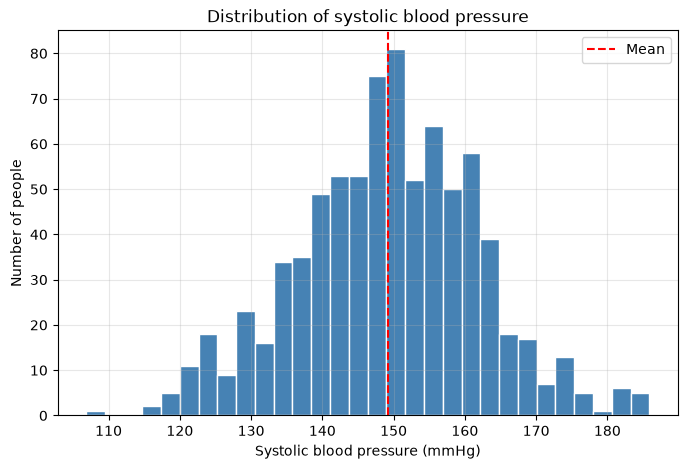

In [49]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["systolic_bp"], bins=30, color="steelblue", edgecolor="white")
ax.axvline(df["systolic_bp"].mean(), color="red", ls="--", label="Mean")
ax.set(title="Distribution of systolic blood pressure",
       xlabel="Systolic blood pressure (mmHg)", ylabel="Number of people")
ax.legend()
plt.show()

The blood pressure has a bell shape. Most people are between 130 and 165 mmHg, and the middle is around 149 mmHg.

### Graph 2 – Box plot of weight by sex

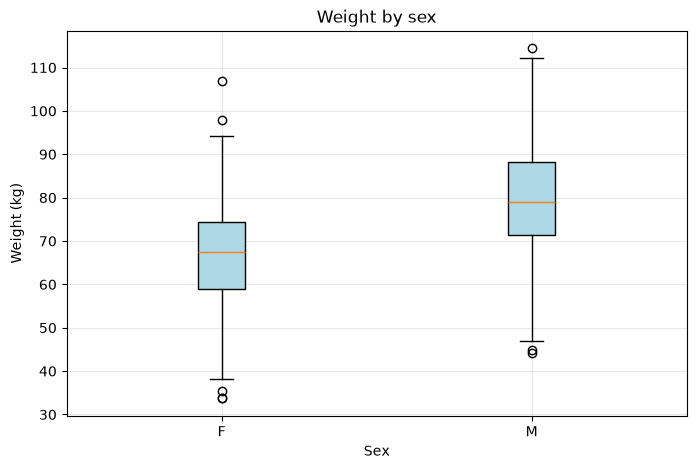

     count  mean   std
sex                   
F      403  67.2  11.8
M      397  79.7  12.6


In [50]:
fig, ax = plt.subplots(figsize=(8, 5))
groups = [df.loc[df["sex"] == s, "weight"] for s in ["F", "M"]]
bp = ax.boxplot(groups, patch_artist=True)
ax.set_xticks([1, 2], ["F", "M"])
for box in bp["boxes"]:
    box.set_facecolor("lightblue")
ax.set(title="Weight by sex", xlabel="Sex", ylabel="Weight (kg)")
plt.show()
print(df.groupby("sex")["weight"].agg(["count", "mean", "std"]).round(1))

Men weigh more than women on average (about 80 kg compared with 67 kg). The spread is about the same in both groups.

### Graph 3 – Bar chart of smokers and non-smokers

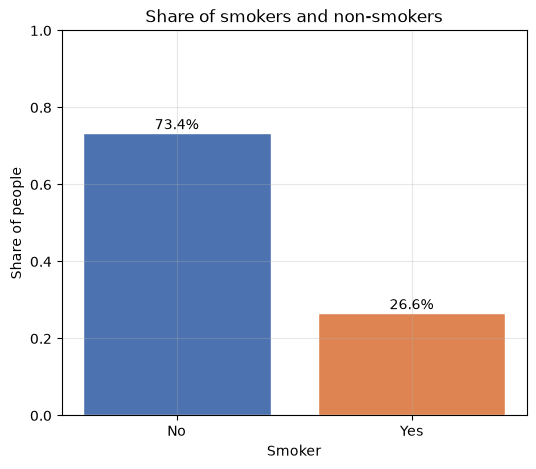

In [51]:
smoker_share = df["smoker"].value_counts(normalize=True).reindex(["No", "Yes"])
fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(smoker_share.index, smoker_share.values, color=["#4c72b0", "#dd8452"], edgecolor="white")
for i, value in enumerate(smoker_share.values):
    ax.text(i, value + 0.01, f"{value:.1%}", ha="center")
ax.set(title="Share of smokers and non-smokers", xlabel="Smoker", ylabel="Share of people", ylim=(0, 1))
plt.show()

About 27% of the people are smokers (213 of 800) and 73% are non-smokers.

### Graph 4 – Scatter plot of age and systolic blood pressure

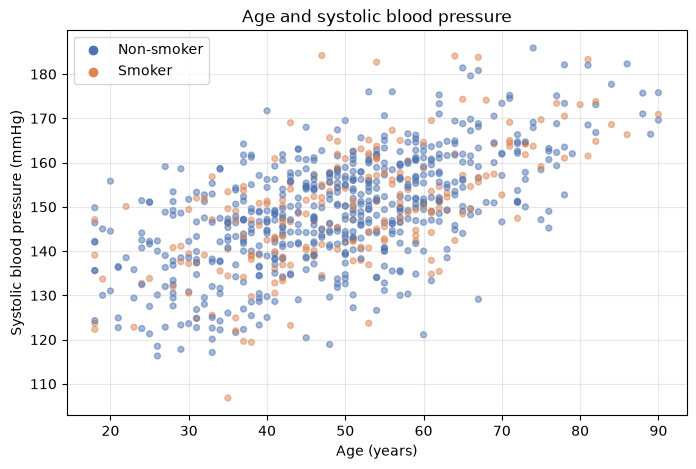

Correlation between age and blood pressure: 0.61


In [52]:
fig, ax = plt.subplots(figsize=(8, 5))
colours = np.where(df["smoker"] == "Yes", "#dd8452", "#4c72b0")
ax.scatter(df["age"], df["systolic_bp"], c=colours, alpha=0.5, s=18)
ax.scatter([], [], c="#4c72b0", label="Non-smoker")
ax.scatter([], [], c="#dd8452", label="Smoker")
ax.set(title="Age and systolic blood pressure", xlabel="Age (years)", ylabel="Systolic blood pressure (mmHg)")
ax.legend()
plt.show()
print("Correlation between age and blood pressure:", round(df["age"].corr(df["systolic_bp"]), 2))

Blood pressure goes up when age goes up (correlation 0.61). Age is clearly important in this data. Smokers (orange) and non-smokers (blue) are mixed together all over the plot. The graphs help me see patterns, but they do not prove cause and effect.

## 4. Disease share and simulation

In [53]:
cases = int(df["disease"].sum())
total = len(df)
p_disease = cases / total
print(f"People with the disease: {cases} of {total}")
print(f"Real share with the disease: {p_disease:.4f} = {p_disease * 100:.2f}%")

# Simulate 1,000 people. Everyone has the same probability p_disease of being sick.
n_sim = 1000
simulated = rng.binomial(1, p_disease, size=n_sim)
print(f"\nSimulated sick people out of {n_sim}: {int(simulated.sum())}")
print(f"Simulated share: {simulated.mean():.4f} = {simulated.mean() * 100:.2f}%")
print(f"Difference (simulated - real): {(simulated.mean() - p_disease) * 100:+.2f} percentage points")

People with the disease: 47 of 800
Real share with the disease: 0.0587 = 5.88%

Simulated sick people out of 1000: 54
Simulated share: 0.0540 = 5.40%
Difference (simulated - real): -0.47 percentage points


In the real data 5.88% of the people have the disease (47 of 800). In my simulation of 1,000 people, 54 were sick, which is 5.4%. The two values are close. A small difference is normal because the simulation is random. To see how big the random difference usually is, I repeat the simulation 10,000 times.

Average of the simulated shares: 0.0587
Spread (standard deviation):     0.0074
Middle 95% of the results:       0.0450 to 0.0740
Formula for the spread, sqrt(p(1-p)/n): 0.0074


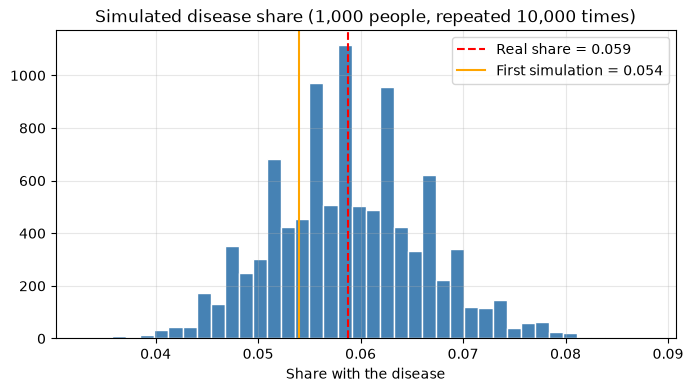

In [54]:
repeats = 10_000
sim_shares = rng.binomial(n_sim, p_disease, size=repeats) / n_sim
low, high = np.percentile(sim_shares, [2.5, 97.5])
print(f"Average of the simulated shares: {sim_shares.mean():.4f}")
print(f"Spread (standard deviation):     {sim_shares.std():.4f}")
print(f"Middle 95% of the results:       {low:.4f} to {high:.4f}")
print(f"Formula for the spread, sqrt(p(1-p)/n): {np.sqrt(p_disease * (1 - p_disease) / n_sim):.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sim_shares, bins=40, color="steelblue", edgecolor="white")
ax.axvline(p_disease, color="red", ls="--", label=f"Real share = {p_disease:.3f}")
ax.axvline(simulated.mean(), color="orange", label=f"First simulation = {simulated.mean():.3f}")
ax.set(title="Simulated disease share (1,000 people, repeated 10,000 times)", xlabel="Share with the disease")
ax.legend()
plt.show()

**What this means.** With 1,000 people, the simulated share is normally within about ±1.5 percentage points of the real share (middle 95%: 4.5% to 7.4%). My first result of 5.4% is well inside this range. So the simulation agrees with the real data. This is expected, because I use the real share as the probability. The simulation does not prove anything new. It only shows how much a share can change by pure chance.

## 5. Confidence interval for the mean systolic blood pressure

I make a 95% confidence interval with two methods:
1. **Formula method:** mean ± critical value × standard error. I do it with the normal approximation (z = 1.96) and with the t distribution.
2. **Bootstrap:** I take 10,000 new samples from my data (with replacement), calculate the mean of each sample and use the 2.5th and 97.5th percentiles.

In [55]:
bp = df["systolic_bp"].to_numpy()
n = len(bp)
mean_bp = bp.mean()
sd_bp = bp.std(ddof=1)
se_bp = sd_bp / np.sqrt(n)

# Method 1a: normal approximation
z = stats.norm.ppf(0.975)
ci_z = (mean_bp - z * se_bp, mean_bp + z * se_bp)

# Method 1b: t distribution
ci_t = stats.t.interval(0.95, df=n - 1, loc=mean_bp, scale=se_bp)

# Method 2: bootstrap (percentile)
B = 10_000
boot_means = rng.choice(bp, size=(B, n), replace=True).mean(axis=1)
ci_boot = np.percentile(boot_means, [2.5, 97.5])

ci_table = pd.DataFrame({"Lower": [ci_z[0], ci_t[0], ci_boot[0]],
                         "Upper": [ci_z[1], ci_t[1], ci_boot[1]]},
                        index=["Normal approximation", "t distribution", "Bootstrap"])
ci_table["Width"] = ci_table["Upper"] - ci_table["Lower"]
print(f"n = {n}, mean = {mean_bp:.2f}, standard deviation = {sd_bp:.2f}, standard error = {se_bp:.3f}")
ci_table.round(2)

n = 800, mean = 149.18, standard deviation = 12.79, standard error = 0.452


,Lower,Upper,Width
Normal approximation,148.29,150.07,1.77
t distribution,148.29,150.07,1.78
Bootstrap,148.32,150.07,1.75


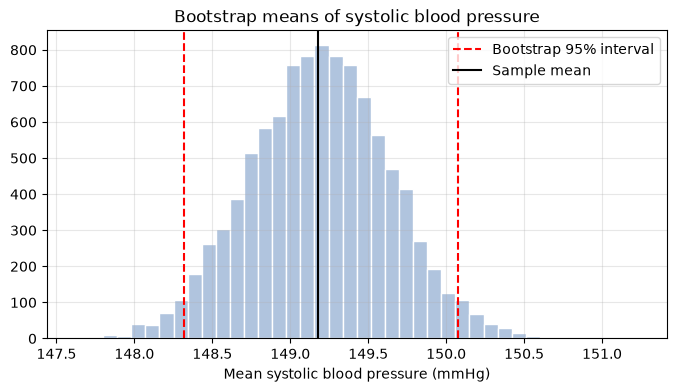

In [56]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(boot_means, bins=40, color="lightsteelblue", edgecolor="white")
ax.axvline(ci_boot[0], color="red", ls="--", label="Bootstrap 95% interval")
ax.axvline(ci_boot[1], color="red", ls="--")
ax.axvline(mean_bp, color="black", label="Sample mean")
ax.set(title="Bootstrap means of systolic blood pressure", xlabel="Mean systolic blood pressure (mmHg)")
ax.legend()
plt.show()

### Comparing the confidence intervals
The three intervals are almost the same:
- Normal approximation: 148.29 to 150.07 mmHg
- t distribution: 148.29 to 150.07 mmHg
- Bootstrap: 148.32 to 150.07 mmHg

The widths are all about 1.8 mmHg. The differences are tiny because the sample is big (n = 800). The central limit theorem says that the mean of a big sample is close to normally distributed, so the formula works well. The bootstrap does not use a formula, it only resamples the data. It gives the same answer, so my result does not depend on which method I use.

The intervals say that a population mean around 149.2 mmHg fits the data well, and the narrow width means the mean is estimated with good precision (if these 800 people are a good picture of the population).

**Note:** "95%" tells how well the method works in the long run. If I repeated the study many times, about 95% of the intervals made this way would contain the true mean. It does **not** mean that this one interval has a 95% chance to contain it.

### 5.1 Extra checks of the two methods

With n = 800 all methods agree, so that does not show when they are different. I do two extra checks:
1. I compare my bootstrap with the bootstrap function in SciPy (`scipy.stats.bootstrap`, method BCa).
2. **Coverage simulation.** I use the 800 blood pressure values as a small "population" where I know the true mean. I take many samples, make a 95% interval with each method and count how often the interval contains the true mean. A good 95% interval should contain it about 95% of the time. I use a separate seed for this, so my other results do not change.

In [57]:
res = stats.bootstrap((bp,), np.mean, n_resamples=10_000, confidence_level=0.95,
                      method="BCa", random_state=np.random.default_rng(SEED + 2))
print(f"SciPy BCa bootstrap:        {res.confidence_interval.low:.2f} to {res.confidence_interval.high:.2f}")
print(f"My percentile bootstrap:    {ci_boot[0]:.2f} to {ci_boot[1]:.2f}")
print(f"t distribution:             {ci_t[0]:.2f} to {ci_t[1]:.2f}")

SciPy BCa bootstrap:        148.29 to 150.05
My percentile bootstrap:    148.32 to 150.07
t distribution:             148.29 to 150.07


In [58]:
rng_cov = np.random.default_rng(SEED + 1)
true_mean = bp.mean()
n_reps, B_cov = 1000, 1000
rows = []
for n_sample in [10, 30, 100]:
    hits = {"Normal": 0, "t distribution": 0, "Bootstrap": 0}
    for _ in range(n_reps):
        x = rng_cov.choice(bp, size=n_sample, replace=True)
        m, se = x.mean(), x.std(ddof=1) / np.sqrt(n_sample)
        hits["Normal"] += (m - 1.96 * se <= true_mean <= m + 1.96 * se)
        tcrit = stats.t.ppf(0.975, n_sample - 1)
        hits["t distribution"] += (m - tcrit * se <= true_mean <= m + tcrit * se)
        bm = rng_cov.choice(x, size=(B_cov, n_sample), replace=True).mean(axis=1)
        lo, hi = np.percentile(bm, [2.5, 97.5])
        hits["Bootstrap"] += (lo <= true_mean <= hi)
    rows.append({"Sample size": n_sample, **{k: v / n_reps for k, v in hits.items()}})
coverage = pd.DataFrame(rows).set_index("Sample size")
print(f"Random error of each value is about {np.sqrt(0.95 * 0.05 / n_reps):.3f}")
coverage.round(3)

Random error of each value is about 0.007


,Normal,t distribution,Bootstrap
Sample size,,,
10,0.925,0.954,0.905
30,0.951,0.960,0.946
100,0.957,0.959,0.953


**What I found**
- The SciPy BCa interval (148.29 to 150.05) is almost the same as my bootstrap and the t distribution. So my bootstrap code works as expected.
- With n = 100 all three methods contain the true mean 95–96% of the time (95.7%, 95.9%, 95.3%). The random error is about 0.007, so this is close to the wanted 95%. With n = 30 it is also close (95.1%, 96.0%, 94.6%).
- With a very small sample (n = 10) the methods are different. The t distribution is still good (95.4%). The normal interval (92.5%) and the bootstrap (90.5%) are too narrow and miss the true mean too often. This is a known problem of these two methods with small samples.
- My real sample has n = 800, much more than this, so all three methods give the same result.
- Limit: these numbers are for this data, which is close to a normal distribution. They could be different for very skewed data.

## 6. Hypothesis test: do smokers have higher blood pressure?

- **H₀ (null hypothesis):** the mean blood pressure of smokers is not higher than for non-smokers.
- **H₁ (alternative):** smokers have a **higher** mean blood pressure than non-smokers (one-sided).
- **Significance level:** α = 0.05

I use Welch's t-test (`scipy.stats.ttest_ind` with `equal_var=False` and `alternative="greater"`). I chose a one-sided test because the question is only about *higher* blood pressure. I decided this from the assignment question, before I looked at the result.

In [59]:
smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"].to_numpy()
non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"].to_numpy()
obs_diff = smokers.mean() - non_smokers.mean()

print(f"Smokers:     n = {len(smokers)}, mean = {smokers.mean():.2f}, standard deviation = {smokers.std(ddof=1):.2f}")
print(f"Non-smokers: n = {len(non_smokers)}, mean = {non_smokers.mean():.2f}, standard deviation = {non_smokers.std(ddof=1):.2f}")
print(f"Difference in means: {obs_diff:.2f} mmHg")

Smokers:     n = 213, mean = 149.52, standard deviation = 13.27
Non-smokers: n = 587, mean = 149.05, standard deviation = 12.63
Difference in means: 0.47 mmHg


### 6.1 Checking the assumptions

A t-test works best when the data in each group is close to a normal distribution. I check this with Q–Q plots and the Shapiro–Wilk test. I also check if the two groups have a similar spread with Levene's test. The checks do not have to be perfect for Welch's test. It can handle different spreads, and the groups are big. But they show that my choice makes sense.

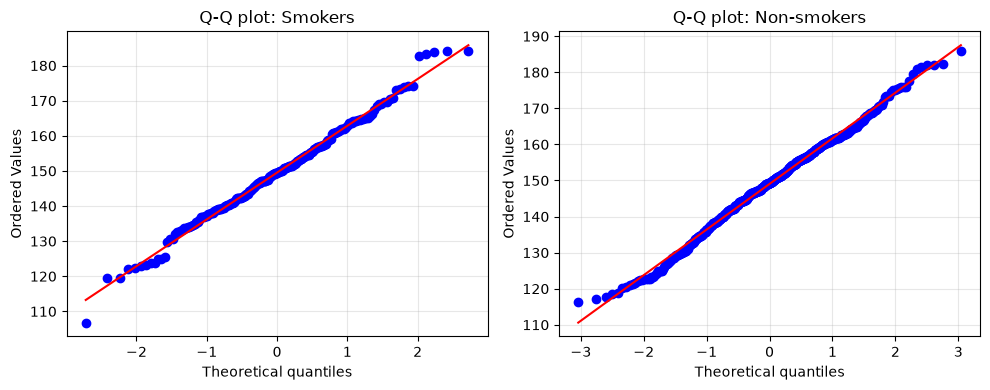

Shapiro-Wilk, smokers:     p = 0.405
Shapiro-Wilk, non-smokers: p = 0.069
Levene (equal spread):     p = 0.569


In [60]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, data, label in zip(axes, [smokers, non_smokers], ["Smokers", "Non-smokers"]):
    stats.probplot(data, dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot: {label}")
plt.tight_layout()
plt.show()

print(f"Shapiro-Wilk, smokers:     p = {stats.shapiro(smokers).pvalue:.3f}")
print(f"Shapiro-Wilk, non-smokers: p = {stats.shapiro(non_smokers).pvalue:.3f}")
lev = stats.levene(smokers, non_smokers)
print(f"Levene (equal spread):     p = {lev.pvalue:.3f}")

In both Q–Q plots the points are close to the straight line. The Shapiro–Wilk test does not reject normality (p = 0.41 for smokers and p = 0.07 for non-smokers, both above 0.05). Levene's test finds no sign of different spreads (p = 0.57). A result that is not significant does not prove that the data is normal. But with 213 and 587 people the central limit theorem also helps, so the t-test is a fair choice. I still use Welch's version because it is safe if the spreads or group sizes are different.

### 6.2 The test

In [61]:
welch = stats.ttest_ind(smokers, non_smokers, equal_var=False, alternative="greater")
print(f"Welch t-test (one-sided):   t = {welch.statistic:.3f}, p = {welch.pvalue:.4f}")

student = stats.ttest_ind(smokers, non_smokers, equal_var=True, alternative="greater")
print(f"Student t-test (one-sided): t = {student.statistic:.3f}, p = {student.pvalue:.4f}")

# Extra check: permutation test (shuffle the smoker labels many times)
pooled = np.concatenate([smokers, non_smokers])
n_perm = 10_000
perm_diffs = np.empty(n_perm)
for i in range(n_perm):
    shuffled = rng.permutation(pooled)
    perm_diffs[i] = shuffled[:len(smokers)].mean() - shuffled[len(smokers):].mean()
p_perm = (np.sum(perm_diffs >= obs_diff) + 1) / (n_perm + 1)
print(f"Permutation test:           p = {p_perm:.4f}")

# Effect size and 95% interval for the difference
n1, n2 = len(smokers), len(non_smokers)
v1, v2 = smokers.var(ddof=1), non_smokers.var(ddof=1)
sd_pooled = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
se_diff = np.sqrt(v1 / n1 + v2 / n2)
df_welch = se_diff**4 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
tcrit = stats.t.ppf(0.975, df_welch)
ci_diff = (obs_diff - tcrit * se_diff, obs_diff + tcrit * se_diff)
boot_diff = (rng.choice(smokers, (B, n1)).mean(axis=1) - rng.choice(non_smokers, (B, n2)).mean(axis=1))
print(f"\nCohen's d (effect size): {obs_diff / sd_pooled:.3f}")
print(f"95% interval for the difference, formula:   {ci_diff[0]:.2f} to {ci_diff[1]:.2f} mmHg")
print(f"95% interval for the difference, bootstrap: {np.percentile(boot_diff, 2.5):.2f} to {np.percentile(boot_diff, 97.5):.2f} mmHg")

Welch t-test (one-sided):   t = 0.450, p = 0.3264
Student t-test (one-sided): t = 0.461, p = 0.3225
Permutation test:           p = 0.3259

Cohen's d (effect size): 0.037
95% interval for the difference, formula:   -1.59 to 2.53 mmHg
95% interval for the difference, bootstrap: -1.59 to 2.55 mmHg


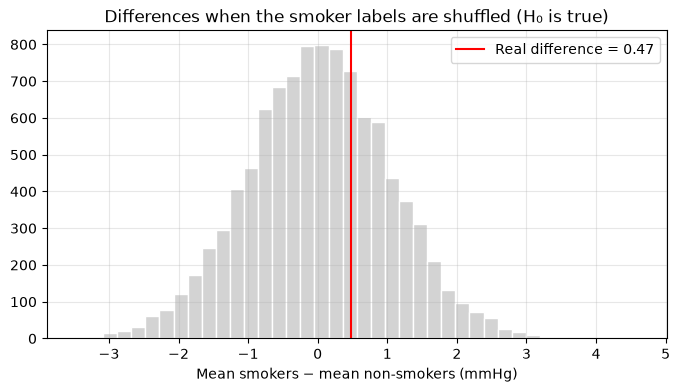

In [62]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(perm_diffs, bins=40, color="lightgray", edgecolor="white")
ax.axvline(obs_diff, color="red", label=f"Real difference = {obs_diff:.2f}")
ax.set(title="Differences when the smoker labels are shuffled (H₀ is true)",
       xlabel="Mean smokers − mean non-smokers (mmHg)")
ax.legend()
plt.show()

**Result.** Smokers have a mean systolic blood pressure of 149.5 mmHg and non-smokers have 149.1 mmHg. The difference is only 0.47 mmHg. The one-sided Welch t-test gives p = 0.326. The Student t-test gives p = 0.322 and the permutation test gives p = 0.326. All p-values are much larger than 0.05. The 95% interval for the difference goes from about −1.6 to +2.5 mmHg and includes zero. The effect size is very small (Cohen's d = 0.04).

**Conclusion**
- I **do not reject H₀**.
- There is not enough evidence that smokers have a higher mean blood pressure than non-smokers.
- This does **not** prove that smoking has no effect. A small effect can be missed (see section 7).

**About the permutation test.** I use it only as an extra check. Shuffling the values assumes that the two groups are equal in everything under H₀, also in their spread. If the spreads are different, this can be a problem. So Welch's test is my main test, because it allows different spreads and group sizes. The permutation test only shows that my conclusion does not change.

**Observational data.** This is an observational study. Even a significant result would not show that smoking *causes* higher blood pressure. Other things, like age, also change blood pressure. In this data the smokers are a little older (50.4 compared with 49.1 years on average), and I did not adjust for this here.

## 7. How reliable is the test? Power simulation

**Power** is how often a test finds an effect when the effect is really there. It does not tell me how likely it is that an effect exists. I simulate it like this:

1. Both groups are normal. Each group gets its own standard deviation from the data (smokers 13.3, non-smokers 12.6) and its real size (213 and 587).
2. I add a true difference δ to the mean of the smokers.
3. I make new random samples, run the same one-sided Welch test as in section 6 and write down if p < 0.05.
4. I repeat this 5,000 times for each δ. The share of significant results is the power. When δ = 0 the share should be close to 5% (the false positive rate), which checks that the test works correctly.

In [63]:
alpha = 0.05
sd_s, sd_ns = smokers.std(ddof=1), non_smokers.std(ddof=1)

def simulate_power(delta, n_smokers=len(smokers), n_non_smokers=len(non_smokers),
                   reps=5000, rng=rng):
    """Estimate the power of the one-sided Welch test by simulation.

    delta : assumed true difference in mean blood pressure (smokers - non-smokers)
    n_smokers, n_non_smokers : group sizes
    reps : number of simulated studies
    Returns the share of simulated studies with p < alpha.
    """
    a = rng.normal(delta, sd_s, size=(reps, n_smokers))
    b = rng.normal(0.0, sd_ns, size=(reps, n_non_smokers))
    result = stats.ttest_ind(a, b, axis=1, equal_var=False, alternative="greater")
    return np.mean(result.pvalue < alpha)

deltas = [0, 0.5, 1, 2, 3, 4, 5, 6, 8, 10]
power_table = pd.DataFrame({"True difference (mmHg)": deltas,
                            "Estimated power": [simulate_power(d) for d in deltas]})
power_table

,True difference (mmHg),Estimated power
0,0.0,0.042
1,0.5,0.120
2,1.0,0.248
3,2.0,0.605
4,3.0,0.884
5,4.0,0.984
6,5.0,0.999
7,6.0,1.000
8,8.0,1.000
9,10.0,1.000


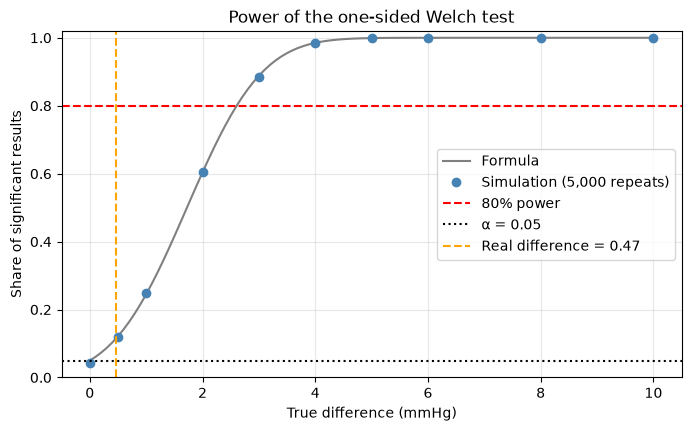

Difference needed for 80% power (formula): 2.61 mmHg
Simulated power at that difference:        0.799
Simulated power at the real difference (0.47 mmHg): 0.117


In [64]:
# Formula (normal approximation) to check the simulation
se_theory = np.sqrt(sd_s**2 / len(smokers) + sd_ns**2 / len(non_smokers))
grid = np.linspace(0, 10, 101)
theory = 1 - stats.norm.cdf(stats.norm.ppf(1 - alpha) - grid / se_theory)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(grid, theory, color="gray", label="Formula")
ax.plot(power_table.iloc[:, 0], power_table.iloc[:, 1], "o", color="steelblue", label="Simulation (5,000 repeats)")
ax.axhline(0.8, color="red", ls="--", label="80% power")
ax.axhline(alpha, color="black", ls=":", label="α = 0.05")
ax.axvline(obs_diff, color="orange", ls="--", label=f"Real difference = {obs_diff:.2f}")
ax.set(title="Power of the one-sided Welch test", xlabel="True difference (mmHg)",
       ylabel="Share of significant results", ylim=(0, 1.02))
ax.legend()
plt.show()

mde = (stats.norm.ppf(1 - alpha) + stats.norm.ppf(0.8)) * se_theory
print(f"Difference needed for 80% power (formula): {mde:.2f} mmHg")
print(f"Simulated power at that difference:        {simulate_power(mde):.3f}")
print(f"Simulated power at the real difference ({obs_diff:.2f} mmHg): {simulate_power(obs_diff):.3f}")

### What the power results mean
The power gets higher when the true difference gets bigger.

When the true difference is 0, the test is significant in 4.2% of the runs. This is close to the chosen 5%, so the test works as expected.

With a true difference of 1 mmHg the power is about 24.8%. With 2 mmHg it is about 60.5%, and with 3 mmHg it is about 88.4%.

By the formula, a difference of about 2.61 mmHg is needed for 80% power with these group sizes and spreads. The simulation agrees (power 79.9% at that difference).

So the study has a good chance to find differences of about 2.6 mmHg or more. For smaller differences the power is low. At the real difference of 0.47 mmHg the power is only about 11.7%.

This means my non-significant result in section 6 does not prove that smoking and blood pressure are not related. A small difference could be there and still stay undetected. This is why it is important to think about power when a test is not significant.

### 7.1 Does a bigger sample help?

I also test how the power changes with the sample size. I keep the true difference at 2 mmHg and change the size of both groups by a factor (the real study is factor 1). I use a separate seed.

In [65]:
rng_size = np.random.default_rng(SEED + 4)
rows = []
for factor in [0.25, 0.5, 1, 2, 4]:
    n_s, n_ns = int(len(smokers) * factor), int(len(non_smokers) * factor)
    rows.append({"Factor": factor, "Smokers": n_s, "Non-smokers": n_ns,
                 "Power at 2 mmHg": simulate_power(2, n_s, n_ns, reps=3000, rng=rng_size)})
pd.DataFrame(rows).set_index("Factor")

,Smokers,Non-smokers,Power at 2 mmHg
Factor,,,
0.25,53,146,0.236
0.50,106,293,0.374
1.00,213,587,0.609
2.00,426,1174,0.854
4.00,852,2348,0.988


In [66]:
rng_cal = np.random.default_rng(SEED + 3)
type1 = simulate_power(0, reps=20_000, rng=rng_cal)
print(f"Share of significant results when the true difference is 0, with 20,000 repeats: {type1:.4f}")
print(f"Random error is about {np.sqrt(alpha * (1 - alpha) / 20_000):.4f}")

Share of significant results when the true difference is 0, with 20,000 repeats: 0.0481
Random error is about 0.0015


With a bigger sample the power goes up a lot: for a true difference of 2 mmHg it is 23.6% with a quarter of the people, 60.9% with the real sample size and 98.8% with four times as many people. So a bigger study would be able to find smaller differences.

I also repeated the case with no difference with 20,000 repeats. The result is 4.8%, which is inside the random error of 5%. So the first value (4.2%) was only random noise, and the test does not give false alarms more often than it should.

## 8. Why I chose these methods

For each method I explain why I used it, what it assumes, and what its limits are. I used the course material and the documentation of NumPy and SciPy to check this.

**Descriptive statistics.**
- *Why:* I show the mean and the median together. If they are close, there is probably no strong skewness. Min and max show the range and possible extreme values.
- *Limit:* The mean is sensitive to extreme values, so I do not use it alone.

**Simulation of the disease.**
- *Why:* Each simulated person is a yes/no trial with the same probability *p*, so the number of sick people follows a binomial distribution. I use `numpy.random.default_rng` with a seed, which is what the NumPy documentation recommends for new code, so the results are the same every time. I repeat the simulation 10,000 times to see how much the result changes by chance instead of trusting one run.
- *Assumption:* Every person has the same probability and is independent of the others.
- *Limit:* A simulation only copies the probability I give it. It cannot tell me anything new about the real people.

**Confidence interval, two methods.**
- *Normal / t method:* It works because of the central limit theorem. With n = 800 the sample mean is close to normal. z and t are almost the same for a big sample. *Assumption:* independent observations and a large enough sample. *Limit:* it can be wrong for small or very skewed samples.
- *Bootstrap:* It uses repeated sampling from the original data, so it does not need a specific theoretical distribution. I checked my own bootstrap with `scipy.stats.bootstrap`. *Limit:* it still depends on the original sample being a good picture of the population.
- I also ran a coverage simulation to see how often each method contains the true mean for different sample sizes. The two methods agree here, so the result does not depend on the method.

**Checking the assumptions.**
- *Why:* Before the test I used Q–Q plots (`scipy.stats.probplot`), the Shapiro–Wilk test (`scipy.stats.shapiro`) and Levene's test (`scipy.stats.levene`).
- *Limit:* A result that is not significant is not a proof. With a big sample these tests can flag very small differences. So I use them as support and not as the only reason.

**Hypothesis test.**
- *Why:* I chose Welch's t-test because it compares the means of two independent groups and does not need equal spreads or equal group sizes. This fits here, because the groups are not equal in size (213 and 587) and the standard deviations are a bit different (13.3 and 12.6). I use `scipy.stats.ttest_ind` with `equal_var=False`. With `alternative="greater"` it matches my question "do smokers have *higher* blood pressure?".
- *Assumption:* Independent observations and roughly normal means (OK with these group sizes).
- *Limit:* It only compares means.
- *Permutation test (extra check):* I coded it myself by shuffling the group labels with `rng.permutation` from NumPy. It assumes the two groups are exchangeable under H₀, which can be a problem if the spreads are different. So Welch's test is my main test, and the permutation test is only a check.

**Power simulation.**
- *Why:* I cannot get the power from the data alone, because the true effect is not known. So I simulate data with different true differences, the real group sizes and each group's own standard deviation (this fits Welch's test), and I count how often the test is significant. At δ = 0 this also checks the false positive rate. I compare the result with the power formula (normal approximation) to check my simulation. I use the same one-sided test as in section 6.
- *Limit:* The result depends on the effect sizes and standard deviations I choose. Power tells how often the test finds an effect if it is real. It is not the probability that the effect exists.

**Overall limits.**
- The data is observational, so I cannot show cause and effect.
- Age is strongly linked to blood pressure and I did not adjust for it. The smokers are a bit older (50.4 and 49.1 years).
- A p-value is not the probability that H₀ is true.

**Sources used:** course material, NumPy documentation (random Generator), SciPy documentation (`stats.bootstrap`, `ttest_ind`, `shapiro`, `levene`, `probplot`).

## 9. Summary

| Question | Result |
|---|---|
| Disease share | 5.88% (47 of 800). Simulation with 1,000 people: 5.4%. This is normal random variation. |
| Mean systolic blood pressure | 149.2 mmHg. 95% interval about 148.3 to 150.1 mmHg. The normal, t and bootstrap methods agree. |
| Smokers and non-smokers | Difference +0.47 mmHg, one-sided p = 0.33. I do not reject H₀. There is not enough evidence that smokers have higher blood pressure. This is not proof of no effect. |
| Effect size | Cohen's d = 0.04 (very small). 95% interval for the difference: −1.6 to +2.5 mmHg. |
| Are the CI methods good? | With n = 100 all three contain the true mean 95–96% of the time. With n = 10 only the t distribution stays near 95%. |
| Is the test reliable? | False positive rate close to 5%. About 2.6 mmHg difference is needed for 80% power. A bigger sample gives more power. |